# Notebook 8 — Final Model Evaluation

## Objective

Evaluate the selected Logistic Regression model on the held-out
test dataset.

The model and classification threshold were selected in Notebook 7
using training-only validation.

**Selected model:** Balanced Logistic Regression

**Classification threshold:** 0.60

**Test dataset:** 1,409 customers

The model and threshold will remain unchanged throughout final evaluation.

Note: An earlier version of Member 4's Decision Tree notebook accessed
the test dataset. Those results were excluded from the final model
selection, and this limitation will be disclosed in the report.

In [1]:
# =========================================================
# Notebook 8 — Cell 1: Load Final Model and Test Data
# =========================================================

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

# Project directories
data_dir = Path("../data/processed")
models_dir = Path("../models")
reports_dir = Path("../reports")

reports_dir.mkdir(parents=True, exist_ok=True)

# Load the FINAL model selected in Notebook 7
final_model = joblib.load(
    models_dir / "selected_churn_model.joblib"
)

# Load frozen model configuration
config = joblib.load(
    models_dir / "selected_model_config.joblib"
)

# Load held-out test dataset
X_test = pd.read_csv(
    data_dir / "X_test_raw.csv"
)

y_test = pd.read_csv(
    data_dir / "y_test.csv"
).squeeze("columns")

# Retrieve selected threshold
selected_threshold = float(
    config["selected_threshold"]
)

# Display validation information
print("=== FINAL MODEL EVALUATION SETUP ===")

print("\nSelected model:", config["selected_model"])
print("Classification threshold:", selected_threshold)

print("\nModel type:", type(final_model).__name__)

print("\nTest features:", X_test.shape)
print("Test labels:", y_test.shape)

print("\nTest class distribution:")
print(y_test.value_counts())

print("\nMissing values:", X_test.isnull().sum().sum())

# Validate consistency
assert config["selected_model"] == "Logistic Regression"
assert np.isclose(selected_threshold, 0.60)
assert X_test.shape == (1409, 19)
assert len(y_test) == 1409
assert X_test.isnull().sum().sum() == 0
assert set(y_test.unique()) == {0, 1}

print("\nAll final evaluation setup checks passed!")

=== FINAL MODEL EVALUATION SETUP ===

Selected model: Logistic Regression
Classification threshold: 0.6

Model type: Pipeline

Test features: (1409, 19)
Test labels: (1409,)

Test class distribution:
Churn
0    1035
1     374
Name: count, dtype: int64

Missing values: 0

All final evaluation setup checks passed!


In [2]:
# =========================================================
# Cell 2: Final Test Predictions and Evaluation Metrics
# =========================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# 1. Generate churn probabilities
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# 2. Apply the selected threshold (0.60)
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# 3. Calculate final evaluation metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_probabilities
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}

# 4. Display results
print("=== FINAL HELD-OUT TEST EVALUATION ===")

print("\nSelected model: Logistic Regression")
print("Threshold:", selected_threshold)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

# 5. Save final test evaluation
test_results_df = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Threshold": selected_threshold,
    **test_metrics
}])

test_results_df.to_csv(
    reports_dir / "final_test_metrics.csv",
    index=False
)

# 6. Save customer-level predictions
test_predictions_df = X_test.copy()

test_predictions_df["Actual_Churn"] = y_test.to_numpy()
test_predictions_df["Predicted_Churn_Probability"] = test_probabilities
test_predictions_df["Predicted_Churn"] = test_predictions

test_predictions_df.to_csv(
    reports_dir / "final_test_predictions.csv",
    index=False
)

print("\nSaved: final_test_metrics.csv")
print("Saved: final_test_predictions.csv")

print("\nFinal evaluation completed.")

=== FINAL HELD-OUT TEST EVALUATION ===

Selected model: Logistic Regression
Threshold: 0.6
Accuracy: 0.7622
Precision: 0.5399
Recall: 0.7059
F1: 0.6118
ROC-AUC: 0.8416
Average Precision: 0.6326

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409


Saved: final_test_metrics.csv
Saved: final_test_predictions.csv

Final evaluation completed.


=== CONFUSION MATRIX ===
[[810 225]
 [110 264]]

True Negatives: 810
False Positives: 225
False Negatives: 110
True Positives: 264


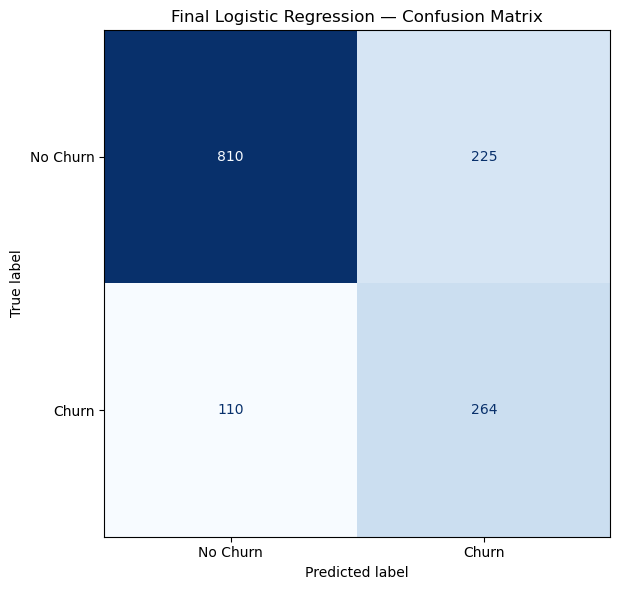


Saved: final_confusion_matrix.png
Saved: final_confusion_matrix.csv


In [3]:
# =========================================================
# Cell 3: Final Test Confusion Matrix
# =========================================================

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("=== CONFUSION MATRIX ===")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Final Logistic Regression — Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    reports_dir / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save confusion matrix counts
cm_df = pd.DataFrame([{
    "True Negatives": tn,
    "False Positives": fp,
    "False Negatives": fn,
    "True Positives": tp
}])

cm_df.to_csv(
    reports_dir / "final_confusion_matrix.csv",
    index=False
)

print("\nSaved: final_confusion_matrix.png")
print("Saved: final_confusion_matrix.csv")

=== CURVE SUMMARY ===
ROC-AUC: 0.8416
PR-AUC (curve area): 0.6316


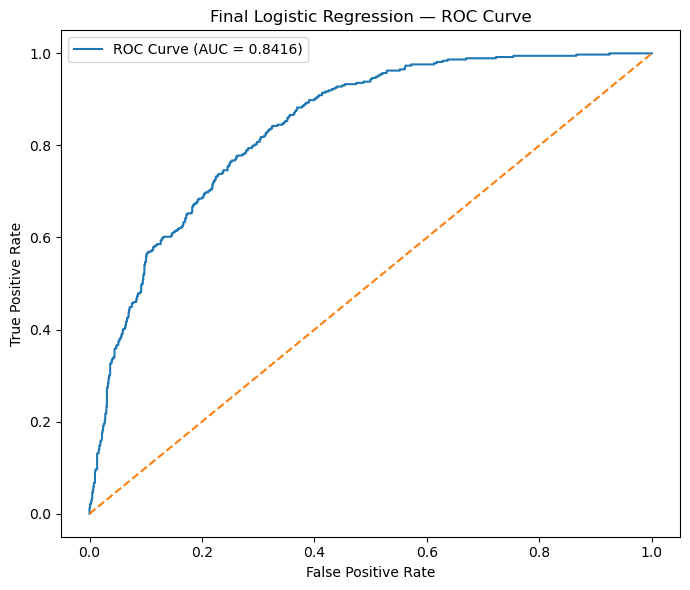

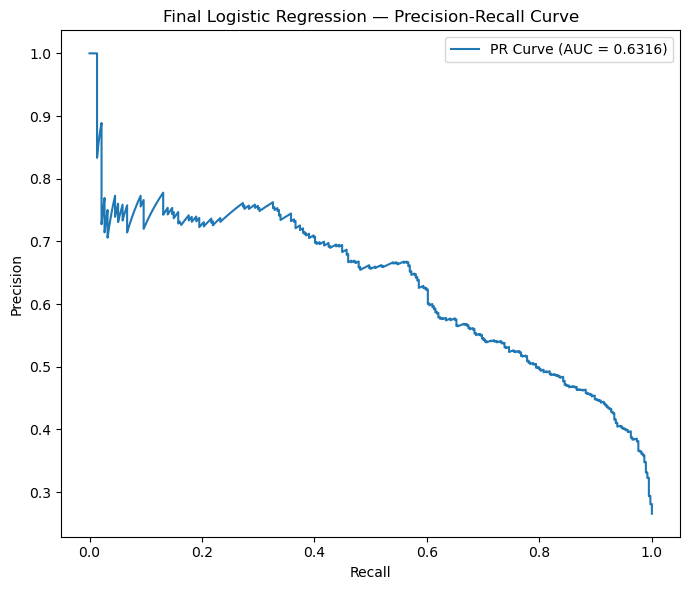


Saved: final_roc_curve.png
Saved: final_pr_curve.png
Saved: final_curve_summary.csv


In [4]:
# =========================================================
# Cell 4: ROC Curve and Precision-Recall Curve
# =========================================================

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

# ROC values
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc_value = auc(fpr, tpr)

# Precision-Recall values
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

pr_auc_value = auc(recall_vals, precision_vals)

print("=== CURVE SUMMARY ===")
print(f"ROC-AUC: {roc_auc_value:.4f}")
print(f"PR-AUC (curve area): {pr_auc_value:.4f}")

# Plot ROC Curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_value:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Logistic Regression — ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(
    reports_dir / "final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot Precision-Recall Curve
plt.figure(figsize=(7, 6))
plt.plot(
    recall_vals,
    precision_vals,
    label=f"PR Curve (AUC = {pr_auc_value:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Logistic Regression — Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(
    reports_dir / "final_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save curve summary
curve_summary_df = pd.DataFrame([{
    "ROC_AUC": roc_auc_value,
    "PR_AUC_curve": pr_auc_value
}])

curve_summary_df.to_csv(
    reports_dir / "final_curve_summary.csv",
    index=False
)

print("\nSaved: final_roc_curve.png")
print("Saved: final_pr_curve.png")
print("Saved: final_curve_summary.csv")

=== PROBABILITY CALIBRATION ===
Brier Score: 0.1687
Log Loss: 0.4967


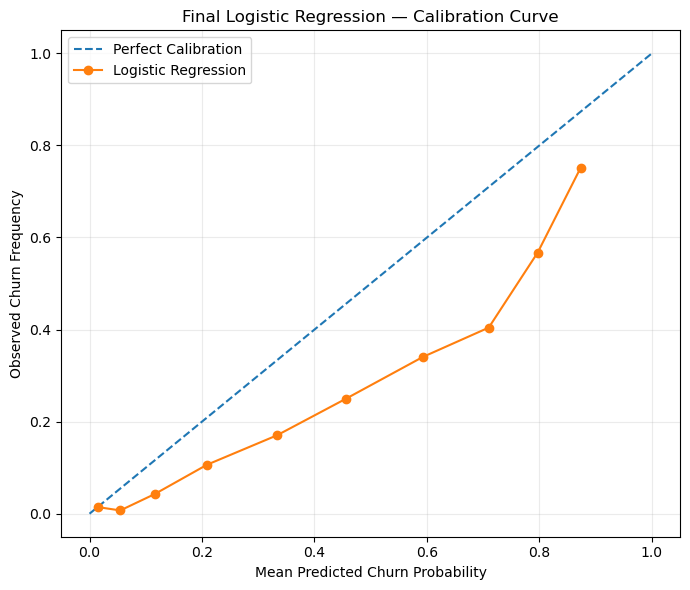


Saved: final_calibration_curve.png
Saved: final_calibration_metrics.csv
Saved: final_calibration_bins.csv


In [5]:
# =========================================================
# Cell 5: Probability Calibration Analysis
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

# 1. Calculate calibration metrics
brier = brier_score_loss(
    y_test,
    test_probabilities
)

logloss = log_loss(
    y_test,
    test_probabilities
)

print("=== PROBABILITY CALIBRATION ===")
print(f"Brier Score: {brier:.4f}")
print(f"Log Loss: {logloss:.4f}")

# 2. Generate calibration curve
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

# 3. Plot reliability diagram
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Observed Churn Frequency")
plt.title("Final Logistic Regression — Calibration Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    reports_dir / "final_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Save calibration summary
calibration_summary = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Threshold": selected_threshold,
    "Brier_Score": brier,
    "Log_Loss": logloss
}])

calibration_summary.to_csv(
    reports_dir / "final_calibration_metrics.csv",
    index=False
)

# 5. Save calibration bin values
calibration_bins = pd.DataFrame({
    "Mean_Predicted_Probability": mean_predicted,
    "Observed_Churn_Frequency": fraction_positive
})

calibration_bins.to_csv(
    reports_dir / "final_calibration_bins.csv",
    index=False
)

print("\nSaved: final_calibration_curve.png")
print("Saved: final_calibration_metrics.csv")
print("Saved: final_calibration_bins.csv")

In [6]:
# =========================================================
# Cell 6: Final Evaluation Summary and Validation
# =========================================================

import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

# Load final evaluation reports
metrics = pd.read_csv(
    reports_dir / "final_test_metrics.csv"
)

confusion = pd.read_csv(
    reports_dir / "final_confusion_matrix.csv"
)

calibration = pd.read_csv(
    reports_dir / "final_calibration_metrics.csv"
)

curves = pd.read_csv(
    reports_dir / "final_curve_summary.csv"
)

# Combine results into a single summary
final_summary = pd.DataFrame([{
    "Model": "Balanced Logistic Regression",
    "Threshold": selected_threshold,
    "Test_Customers": len(y_test),
    "Accuracy": metrics.loc[0, "Accuracy"],
    "Precision": metrics.loc[0, "Precision"],
    "Recall": metrics.loc[0, "Recall"],
    "F1": metrics.loc[0, "F1"],
    "ROC_AUC": metrics.loc[0, "ROC-AUC"],
    "Average_Precision": metrics.loc[0, "Average Precision"],
    "PR_AUC_Trapezoidal": curves.loc[0, "PR_AUC_curve"],
    "Brier_Score": calibration.loc[0, "Brier_Score"],
    "Log_Loss": calibration.loc[0, "Log_Loss"],
    "True_Negatives": confusion.loc[0, "True Negatives"],
    "False_Positives": confusion.loc[0, "False Positives"],
    "False_Negatives": confusion.loc[0, "False Negatives"],
    "True_Positives": confusion.loc[0, "True Positives"]
}])

# Validate counts
assert (
    final_summary.loc[0, [
        "True_Negatives",
        "False_Positives",
        "False_Negatives",
        "True_Positives"
    ]].sum() == len(y_test)
), "Confusion matrix counts do not match test size!"

assert selected_threshold == 0.60, \
    "Final threshold must remain 0.60"

print("=== FINAL MODEL EVALUATION SUMMARY ===")
print(final_summary.T.to_string(header=False))

# Save consolidated summary
final_summary.to_csv(
    reports_dir / "final_evaluation_summary.csv",
    index=False
)

print("\nSaved: final_evaluation_summary.csv")
print("All validation checks passed!")

=== FINAL MODEL EVALUATION SUMMARY ===
Model               Balanced Logistic Regression
Threshold                                    0.6
Test_Customers                              1409
Accuracy                                0.762243
Precision                               0.539877
Recall                                  0.705882
F1                                      0.611819
ROC_AUC                                 0.841634
Average_Precision                       0.632649
PR_AUC_Trapezoidal                      0.631553
Brier_Score                             0.168706
Log_Loss                                 0.49666
True_Negatives                               810
False_Positives                              225
False_Negatives                              110
True_Positives                               264

Saved: final_evaluation_summary.csv
All validation checks passed!


## Final Model Evaluation — Findings and Limitations

### 1. Selected Model

The final selected model is Balanced Logistic Regression with a
classification threshold of 0.60.

The model was selected in Notebook 7 because its training-validation
performance was practically equivalent to XGBoost while providing
simpler interpretation.

### 2. Final Held-Out Test Results

The model was evaluated on 1,409 test customers.

| Metric | Result |
|---|---|
| Accuracy | 0.7622 |
| Precision | 0.5399 |
| Recall | 0.7059 |
| F1-score | 0.6118 |
| ROC-AUC | 0.8416 |
| Average Precision | 0.6326 |

### 3. Confusion Matrix

- True Negatives: 810
- False Positives: 225
- False Negatives: 110
- True Positives: 264

The model correctly identified 264 of 374 customers who churned,
corresponding to approximately 70.59% recall.

However, 110 actual churners were missed, and 225 customers who
did not churn were incorrectly classified as churners.

### 4. Probability Calibration

The Brier Score was 0.1687 and Log Loss was 0.4967.

The calibration curve indicates that the model generally
overestimates churn probabilities.

This may be related to the use of balanced class weights.

Therefore, predicted probabilities should be interpreted
cautiously as relative churn-risk scores rather than reliably
calibrated probabilities.

### 5. Business Implications

The model can help a telecommunications company prioritize
customers for retention activities.

Customers with higher model-estimated churn risk may be
considered for targeted support, contract recommendations,
or service improvements.

However, false positives may increase retention costs,
while false negatives represent missed opportunities to
intervene before customer churn.

The project has not quantified the actual financial
benefit of these interventions.

### 6. Evaluation Limitations

The final test F1-score (0.6118) was lower than the nested
training-validation estimate (approximately 0.6354).

Model configurations were selected using earlier
training-validation results, which may introduce some
model-selection bias.

An earlier Decision Tree notebook accessed the held-out
test set. Those results were excluded from final model
selection, but this earlier exposure is a limitation of
the evaluation process.

The selected model and threshold were not changed after
examining the final test results.

### 7. Conclusion

Balanced Logistic Regression demonstrated useful churn
classification and ranking performance.

Although it identified most actual churners, the model
also produced false positives and false negatives.

Its calibration limitations should be considered when
using predicted scores for customer risk segmentation.

The next stage focuses on high-risk customer profiling
and explaining model predictions.